# PhyRes Demo: Physics-Residual Control on a Planar Quadrotor

This notebook is a guided tour of the **PhyRes** engine, applied to the hardest of
the three benchmark tasks in the suite: a **planar (2D) quadrotor** with an
aerodynamic reality gap the analytic prior cannot see.

We will:

1. Instantiate the `quadrotor2d` benchmark task through the task-agnostic engine.
2. Collect a small exploratory dataset from the *true* system.
3. Train a **physics-residual deep ensemble** world model on top of the
   (deliberately naive) analytic prior.
4. Compare one-step prediction error: **analytic prior vs. residual ensemble**.
5. Visualise the ensemble's **epistemic uncertainty** as a 2D heat map, showing
   it spike out-of-distribution.
6. Run closed-loop hover stabilisation with the new **MPPI** planner, penalised
   by that same uncertainty signal.

Everything below is pure NumPy plus `matplotlib`/`seaborn` for plotting only —
see `pyproject.toml`'s `notebook` extra. Background and citations are in
[SCIENCE.md](SCIENCE.md); the engine's abstractions are in
[src/phyres/environments/base.py](src/phyres/environments/base.py).


In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from phyres.data import collect_random_rollouts
from phyres.ensemble import ResidualEnsembleWorldModel
from phyres.environments import make_task
from phyres.planners import MPPIPlanner

warnings.filterwarnings("ignore")
SEED = 0
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"prior": "#9aa5b1", "model": "#2f6fed", "uncertainty": "#e0621f", "trajectory": "#1f9e6e"}
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titleweight"] = "bold"


## 1. The benchmark task: a planar quadrotor with an unmodeled reality gap

`make_task("quadrotor2d", seed=SEED)` builds a matched
`Quadrotor2DPrior` / `Quadrotor2DSystem` pair (see
[src/phyres/environments/quadrotor2d.py](src/phyres/environments/quadrotor2d.py))
plus a hover cost function -- exactly the same `BenchmarkTask` contract the
pendulum and cart-pole tasks use, which is what makes the engine
task-agnostic.

State `s = (x, y, phi, x_dot, y_dot, phi_dot)`; actions are the two rotor
thrusts `(F_left, F_right)`, each in `[0, thrust_max]`.

* **`Quadrotor2DPrior`** assumes textbook vacuum kinematics: two point thrusts
  acting through the centre of mass, no aerodynamics at all.
* **`Quadrotor2DSystem`** (the "real world") adds quadratic aerodynamic drag on
  both translational velocities and a *ground-effect* lift boost that grows
  sharply as the vehicle nears the floor -- a genuinely nonlinear effect a
  vacuum-kinematics prior has no way to represent.


In [2]:
task = make_task("quadrotor2d", seed=SEED)
prior, true_system = task.prior, task.true_system

print(f"task: {task.name!r}")
print(f"state_dim={prior.state_dim}  action_dim={prior.action_dim}  "
      f"action bounds=[{prior.action_low}, {prior.action_high}]")
print(f"hover thrust per rotor: {prior.hover_thrust:.3f} N "
      f"(mass={prior.mass} kg, arm={prior.arm} m)")
print()
print("reality gap (true system only):")
print(f"  aerodynamic drag coefficient : {true_system.drag_coeff}")
print(f"  ground-effect gain / height  : {true_system.ground_effect_gain} / "
      f"{true_system.ground_effect_height} m")
print(f"  ground contact stiffness/damp: {true_system.contact_stiffness} / "
      f"{true_system.contact_damping}")


task: 'quadrotor2d'
state_dim=6  action_dim=2  action bounds=[[0. 0.], [6. 6.]]
hover thrust per rotor: 2.453 N (mass=0.5 kg, arm=0.15 m)

reality gap (true system only):
  aerodynamic drag coefficient : 0.15
  ground-effect gain / height  : 0.35 / 0.3 m
  ground contact stiffness/damp: 300.0 / 30.0


## 2. Collecting exploratory data

Exploration uses correlated (Ornstein-Uhlenbeck-style) random rotor thrusts
rather than white noise, centred on hover thrust with a reduced amplitude --
independent full-range thrust commands are extremely torque-violent for a
small quadrotor (`arm / inertia` is a large gain onto roll acceleration), so a
"real flight-test engineer" would keep exploration inside a flyable envelope
too. This is encoded once in the task itself
(`task.explore_center`, `task.explore_scale`, `task.explore_episode_len`) and
`collect_random_rollouts` is otherwise completely generic across all three
benchmark tasks.


collected 1920 transitions (1728 train / 192 held-out) in 0.2s


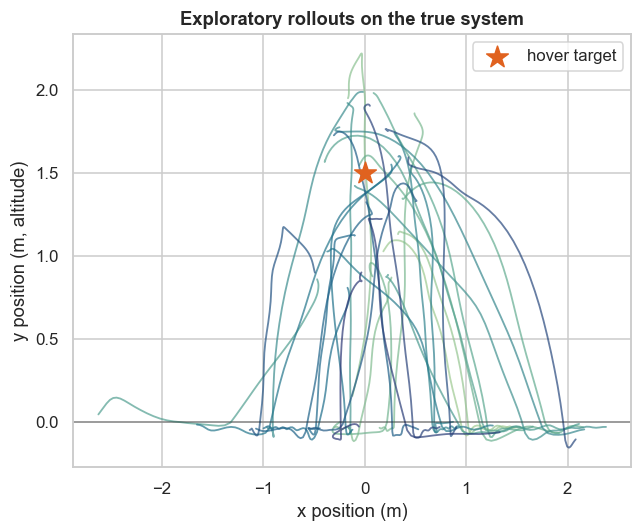

In [3]:
t0 = time.time()
states, actions, next_states = collect_random_rollouts(
    true_system, prior.action_low, prior.action_high,
    n_episodes=32, episode_len=task.explore_episode_len, seed=SEED,
    center=task.explore_center, amplitude_scale=task.explore_scale,
)
n_train = int(0.9 * len(states))
train = (states[:n_train], actions[:n_train], next_states[:n_train])
test = (states[n_train:], actions[n_train:], next_states[n_train:])
print(f"collected {len(states)} transitions ({n_train} train / {len(states) - n_train} held-out) "
      f"in {time.time() - t0:.1f}s")

fig, ax = plt.subplots(figsize=(6, 5))
episode_len = task.explore_episode_len
n_episodes = len(states) // episode_len
colors = sns.color_palette("crest", n_episodes)
for ep in range(n_episodes):
    sl = slice(ep * episode_len, (ep + 1) * episode_len)
    ax.plot(states[sl, 0], states[sl, 1], color=colors[ep], alpha=0.7, lw=1.2)
ax.scatter([0], [1.5], marker="*", s=220, color=PALETTE["uncertainty"], zorder=5, label="hover target")
ax.set_xlabel("x position (m)")
ax.set_ylabel("y position (m, altitude)")
ax.set_title("Exploratory rollouts on the true system")
ax.axhline(0.0, color="k", lw=1, alpha=0.4)
ax.legend()
fig.tight_layout()


## 3. Training the physics-residual ensemble

`ResidualEnsembleWorldModel` trains `K` bootstrapped, independently
initialised residual MLPs on `s' - f_phys(s, a)`, entirely generically over
the task -- it reads `state_dim`, `feature_dim` and `circular_dims`
(here just the roll angle `phi`) straight off `prior`.


trained 5 members in 25.5s


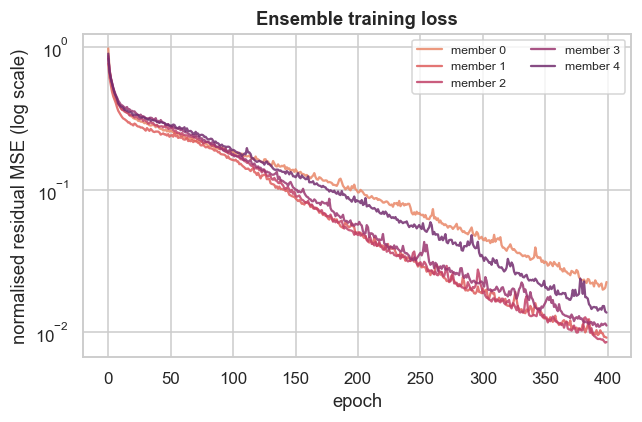

In [4]:
model = ResidualEnsembleWorldModel(prior, n_members=5, hidden=(64, 64), seed=SEED)
t0 = time.time()
histories = model.fit(*train, epochs=400)
print(f"trained {model.n_members} members in {time.time() - t0:.1f}s")

fig, ax = plt.subplots(figsize=(6, 4))
for k, h in enumerate(histories):
    ax.plot(h, color=sns.color_palette("flare", len(histories))[k], alpha=0.85, label=f"member {k}")
ax.set_yscale("log")
ax.set_xlabel("epoch")
ax.set_ylabel("normalised residual MSE (log scale)")
ax.set_title("Ensemble training loss")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()


## 4. Prediction error: analytic prior vs. residual ensemble

Held-out one-step RMSE, broken down **per state dimension**. The roll
dimensions (`phi`, `phi_dot`) get no benefit from residual learning because
the prior already predicts them exactly -- the true system's reality gap
(drag, ground effect) only touches translational motion. That selectivity is
itself a useful sanity check: the residual isn't hallucinating improvement
where the prior was already correct.


overall RMSE  prior: 0.2536   residual ensemble: 0.1012   (2.50x reduction)


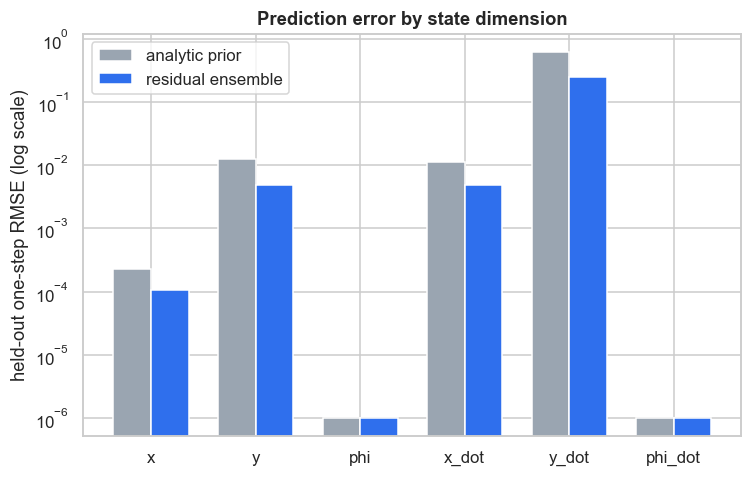

In [5]:
def rmse_per_dim(pred, target):
    err = prior.wrap_state(pred - target)
    return np.sqrt(np.mean(err**2, axis=0))

pred_prior = prior.forward(*test[:2])
pred_model, _ = model.predict(*test[:2])
err_prior = rmse_per_dim(pred_prior, test[2])
err_model = rmse_per_dim(pred_model, test[2])

dims = ["x", "y", "phi", "x_dot", "y_dot", "phi_dot"]
eps = 1e-6
fig, ax = plt.subplots(figsize=(7, 4.5))
x = np.arange(len(dims))
width = 0.36
ax.bar(x - width / 2, err_prior + eps, width, color=PALETTE["prior"], label="analytic prior")
ax.bar(x + width / 2, err_model + eps, width, color=PALETTE["model"], label="residual ensemble")
ax.set_yscale("log")
ax.set_xticks(x)
ax.set_xticklabels(dims)
ax.set_ylabel("held-out one-step RMSE (log scale)")
ax.set_title("Prediction error by state dimension")
ax.legend()
fig.tight_layout()

overall_prior = np.sqrt(np.mean(prior.wrap_state(pred_prior - test[2]) ** 2))
overall_model = np.sqrt(np.mean(prior.wrap_state(pred_model - test[2]) ** 2))
print(f"overall RMSE  prior: {overall_prior:.4f}   residual ensemble: {overall_model:.4f}   "
      f"({overall_prior / overall_model:.2f}x reduction)")


## 5. Epistemic uncertainty heat map

The reality gap this task is built around -- drag and ground effect -- lives
almost entirely in the `(y, y_dot)` plane (altitude vs. vertical speed), so we
sweep a grid over exactly those two dimensions (holding `x = x_dot = phi =
phi_dot = 0` and both rotors at hover thrust) and plot the ensemble's
disagreement `d(s, a)` at every grid point, with the training data overlaid.
Disagreement should stay low where the training rollouts actually visited,
and grow sharply in the unvisited corners -- the model "knowing what it
doesn't know."


mean disagreement near training distribution: 0.0064
mean disagreement in the far corners (OOD)   : 0.1560
ratio: 24.2x


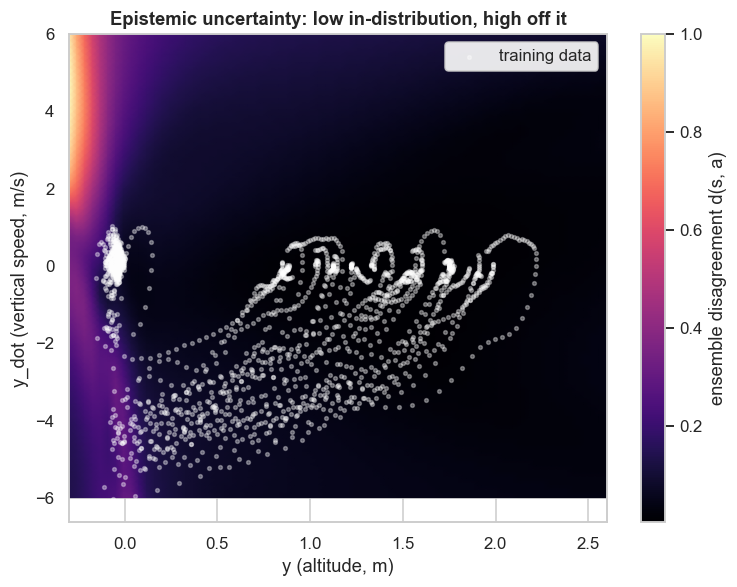

In [6]:
y_grid = np.linspace(-0.3, 2.6, 70)
ydot_grid = np.linspace(-6.0, 6.0, 70)
YY, YD = np.meshgrid(y_grid, ydot_grid)
n_grid = YY.size

s_grid = np.zeros((n_grid, prior.state_dim))
s_grid[:, 1] = YY.ravel()
s_grid[:, 4] = YD.ravel()
a_grid = np.full((n_grid, prior.action_dim), prior.hover_thrust)

_, disagreement = model.predict(s_grid, a_grid)
D = disagreement.reshape(YY.shape)

fig, ax = plt.subplots(figsize=(7, 5.5))
mesh = ax.pcolormesh(YY, YD, D, shading="gouraud", cmap="magma")
cbar = fig.colorbar(mesh, ax=ax)
cbar.set_label("ensemble disagreement d(s, a)")
ax.scatter(states[:, 1], states[:, 4], s=6, color="white", alpha=0.35, label="training data")
ax.set_xlabel("y (altitude, m)")
ax.set_ylabel("y_dot (vertical speed, m/s)")
ax.set_title("Epistemic uncertainty: low in-distribution, high off it")
ax.legend(loc="upper right", framealpha=0.9)
fig.tight_layout()

in_dist_mask = (np.abs(YY - 1.5) < 0.4) & (np.abs(YD) < 1.0)
ood_mask = (YY < 0.0) | (YY > 2.3) | (np.abs(YD) > 5.0)
print(f"mean disagreement near training distribution: {D[in_dist_mask].mean():.4f}")
print(f"mean disagreement in the far corners (OOD)   : {D[ood_mask].mean():.4f}")
print(f"ratio: {D[ood_mask].mean() / D[in_dist_mask].mean():.1f}x")


## 6. Closed-loop hover stabilisation with MPPI

Finally, the new [`MPPIPlanner`](src/phyres/planners/mppi.py) drives the
*true* system in closed loop, using the residual ensemble as its world model
and penalising imagined trajectories by `uncertainty_weight * disagreement` --
exactly the same risk-aware mechanism as `CEMPlanner`, but with smooth,
information-theoretic trajectory weighting instead of hard elite selection.
The vehicle starts with a $0.35$ rad roll perturbation and $0.3$ m lateral
offset, and must recover to hover at the target (dashed star).


In [7]:
planner = MPPIPlanner(
    world_model=model,
    cost_fn=task.cost_fn,
    action_dim=prior.action_dim,
    action_low=prior.action_low,
    action_high=prior.action_high,
    horizon=task.plan_horizon,
    n_samples=400,
    temperature=0.3,
    noise_std=np.full(2, 0.5),
    uncertainty_weight=0.2,
    init_mean=task.planner_init_mean,
    seed=SEED,
)
planner.reset()
s = true_system.reset(state=task.initial_state)

T = 200
trajectory = [s.copy()]
action_log, cost_log = [], []
t0 = time.time()
for _ in range(T):
    a = planner.plan(s)
    cost_log.append(float(task.cost_fn(s[None, :], a[None, :])[0]))
    action_log.append(a.copy())
    s = true_system.step(a)
    trajectory.append(s.copy())
trajectory = np.array(trajectory)
action_log = np.array(action_log)
cost_log = np.array(cost_log)
print(f"closed-loop rollout: {T} steps in {time.time() - t0:.1f}s")
print(f"cost, first 10 steps : {cost_log[:10].mean():.3f}")
print(f"cost, last 30 steps  : {cost_log[-30:].mean():.3f}")
print(f"final state (x, y, phi): "
      f"({trajectory[-1, 0]:.3f}, {trajectory[-1, 1]:.3f}, {trajectory[-1, 2]:.3f})")


closed-loop rollout: 200 steps in 31.1s
cost, first 10 steps : 0.476
cost, last 30 steps  : 0.016
final state (x, y, phi): (0.046, 1.495, 0.021)


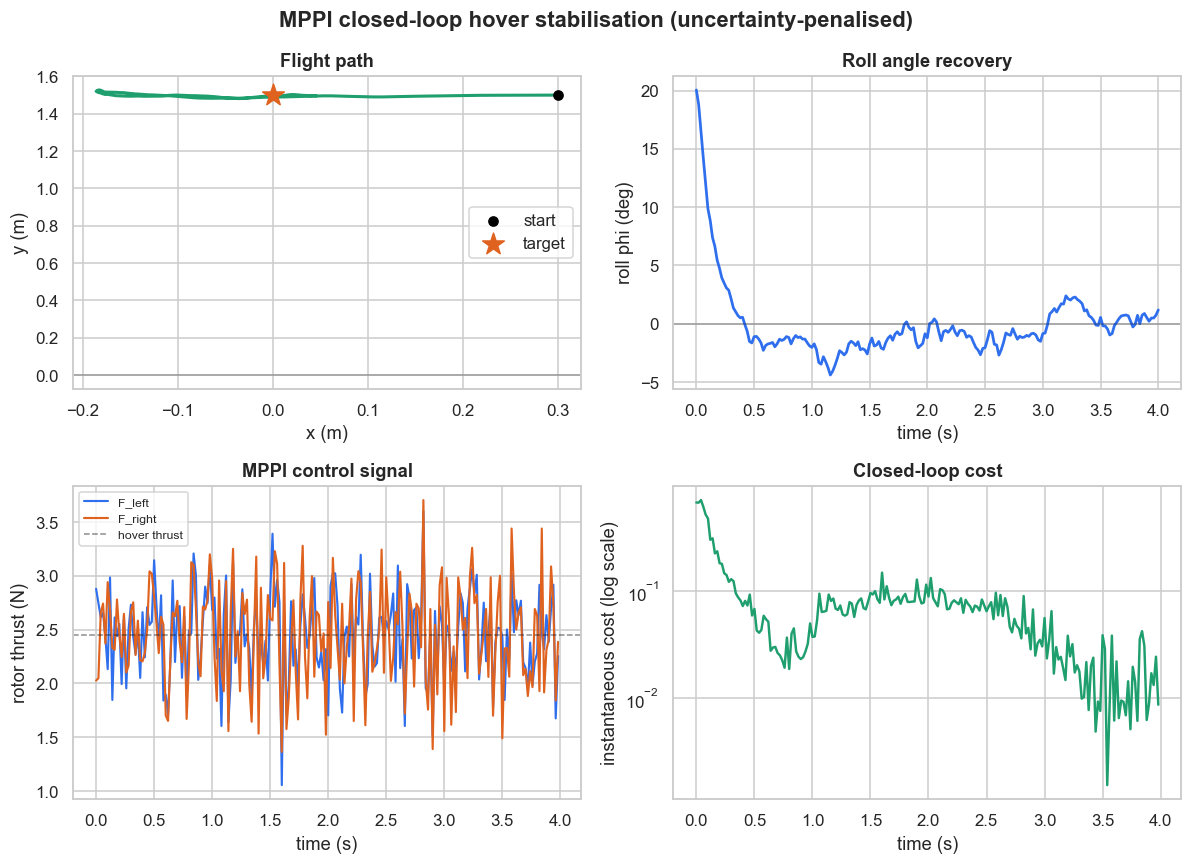

In [8]:
t = np.arange(T + 1) * true_system.dt
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

ax = axes[0, 0]
ax.plot(trajectory[:, 0], trajectory[:, 1], color=PALETTE["trajectory"], lw=2)
ax.scatter([task.initial_state[0]], [task.initial_state[1]], color="black", zorder=5, label="start")
ax.scatter([0.0], [1.5], marker="*", s=220, color=PALETTE["uncertainty"], zorder=5, label="target")
ax.axhline(0.0, color="k", lw=1, alpha=0.3)
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Flight path")
ax.legend()

ax = axes[0, 1]
ax.plot(t, np.degrees(trajectory[:, 2]), color=PALETTE["model"], lw=1.8)
ax.axhline(0.0, color="k", lw=1, alpha=0.3)
ax.set_xlabel("time (s)")
ax.set_ylabel("roll phi (deg)")
ax.set_title("Roll angle recovery")

ax = axes[1, 0]
ax.plot(t[:-1], action_log[:, 0], label="F_left", color=PALETTE["model"], lw=1.4)
ax.plot(t[:-1], action_log[:, 1], label="F_right", color=PALETTE["uncertainty"], lw=1.4)
ax.axhline(prior.hover_thrust, color="k", lw=1, ls="--", alpha=0.5, label="hover thrust")
ax.set_xlabel("time (s)")
ax.set_ylabel("rotor thrust (N)")
ax.set_title("MPPI control signal")
ax.legend(fontsize=8)

ax = axes[1, 1]
ax.plot(t[:-1], cost_log, color=PALETTE["trajectory"], lw=1.6)
ax.set_yscale("log")
ax.set_xlabel("time (s)")
ax.set_ylabel("instantaneous cost (log scale)")
ax.set_title("Closed-loop cost")

fig.suptitle("MPPI closed-loop hover stabilisation (uncertainty-penalised)", fontweight="bold")
fig.tight_layout()


## Summary

* **Section 4** showed the residual ensemble cuts held-out one-step
  prediction error dramatically on the dimensions that actually have a
  reality gap (translational motion), while correctly leaving the
  already-exact roll dynamics untouched.
* **Section 5** showed the ensemble's disagreement is structured exactly the
  way the theory predicts: small near the training distribution, large in
  unvisited corners of state space -- a usable epistemic-uncertainty signal,
  not just noise.
* **Section 6** closed the loop: MPPI, driven by that hybrid model and
  penalised by its own uncertainty, recovers the quadrotor from a roll
  perturbation to a stable hover using only exploratory data and no access to
  the true dynamics.

See [SCIENCE.md](SCIENCE.md) for the full formulation (including the
information-theoretic derivation of MPPI's trajectory weighting), and
`experiments/run_benchmark.py --task <pendulum|cartpole|quadrotor2d> --planner
<cem|mppi>` to reproduce any task/planner combination from the command line.
